# Лабораторная работа 1 и 2 

`Исполнитель`: Александр Сорокин (563584)

`Данные`: Economics_of_Cities.csv

In [1]:
#  Активируем библиотеки

import numpy as np
import pandas as pd

import seaborn as sns

import matplotlib
import matplotlib.pyplot as plt
matplotlib.style.use('ggplot')
%matplotlib inline

#  Активируем 3 процедуры иерархического кластерного анализа
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

In [2]:
# sep=";" - разделитель столбцов, decimal="," - разделитель дробной части
df_default = pd.read_csv('Economics_of_Cities.csv', sep=";", decimal=",")

## Исследование данных

In [3]:
df_default.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 4 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   City    48 non-null     object 
 1   Work    48 non-null     int64  
 2   Price   48 non-null     float64
 3   Salary  48 non-null     float64
dtypes: float64(2), int64(1), object(1)
memory usage: 1.6+ KB


In [4]:
# 48 строк, есть тип данных object - для кластеризации он не подходит, 
# поскольку по нему не посчитать расстояние, надо добавить индексы каждому городу

df = df_default.set_index('City')
print(df.shape)
df.head(3)

(48, 3)


,Work,Price,Salary
City,,,
Amsterdam,1714,65.6,49.0
Athens,1792,53.8,30.4
Bogota,2152,37.9,11.5


In [5]:
df.describe()

,Work,Price,Salary
count,48.000000,48.000000,48.000000
mean,1384.958333,68.860417,-378.727083
std,2404.897007,21.784659,2027.338052
min,-9999.000000,30.300000,-9999.000000
25%,1740.750000,49.650000,12.250000
50%,1834.500000,70.500000,40.300000
75%,1972.750000,81.700000,58.700000
max,2375.000000,115.500000,100.000000


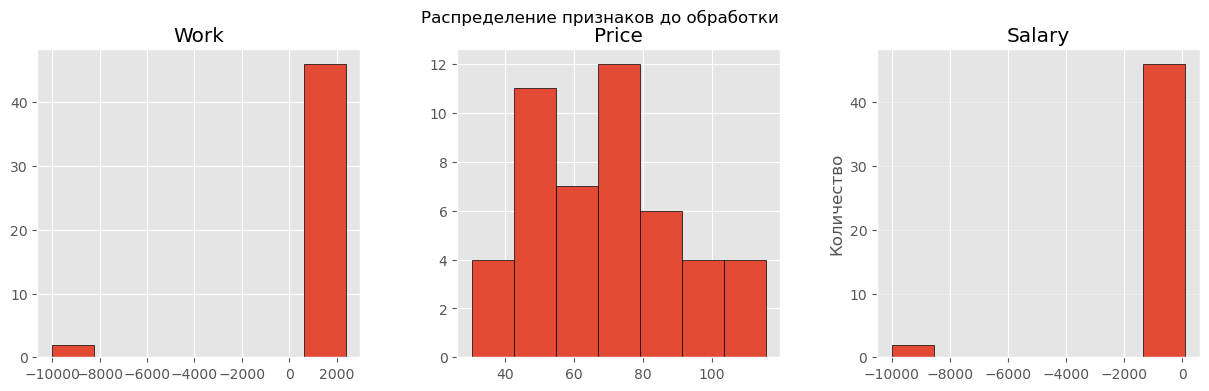

In [6]:
cols = ['Work', 'Price', 'Salary']

df[cols].hist(bins='sturges', edgecolor='black', figsize=(15, 4), layout=(1, 3))

plt.suptitle('Распределение признаков до обработки')
plt.ylabel('Количество')
plt.grid(axis='y', alpha=0.3)
plt.show()

df_descr_1 = df.describe()

In [7]:
# есть явные выбросы в столбцах work и salary (-9999), вероятно заглушки
# нужно вывести города, в которых есть выбросы, для этого посчитаем квартили, IQR и границы до выбросов

In [8]:
# вручную cчитаем квартили порядка 0.25 и 0.75
# завернем в функцию чтобы использовать потом

def IQR(data, col_name):
    Q1 = data[col_name].quantile(0.25)
    Q3 = data[col_name].quantile(0.75)

    # Формула межквартильного размаха
    IQR = Q3 - Q1

    # верхняя и нижняя границы до выбросов
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    # выбросы
    outliers = data[(data[col_name] < lower) | (data[col_name] > upper)]
    return outliers

In [9]:
display(
    IQR(df, 'Work'), 
    IQR(df, 'Price'), 
    IQR(df, 'Salary')
)

,Work,Price,Salary
City,,,
Cairo,-9999,37.1,-9999.0
Hong_Kong,2375,63.8,27.8
Jakarta,-9999,43.6,-9999.0


,Work,Price,Salary
City,,,


,Work,Price,Salary
City,,,
Cairo,-9999,37.1,-9999.0
Jakarta,-9999,43.6,-9999.0


У Каира и Джакарты неизвестны 2 из 3 признаков. Подставить медиану нельзя, потому что получится, что мы выдумали городу две трети данных. 

Оставить NaN нельзя, не посчитаются расстояния и программа ляжет. Поэтому удаляем эти 2 города.

Гонконг вполне реальное значение, просто выходит за границы межквартильного размаха

In [10]:
# замена выбросов на NaN
df_nan = df.replace(-9999, np.nan)
print(df_nan.isna().sum()) # количество заполненных строк в столбцах

df_nan[df_nan.isna().any(axis=1)] # выводим только строки где есть NaN

Work      2
Price     0
Salary    2
dtype: int64


,Work,Price,Salary
City,,,
Cairo,NaN,37.1,NaN
Jakarta,NaN,43.6,NaN


In [11]:
# проверяем, осталось ли еще что-нибудь
display(
    IQR(df_nan, 'Work'), 
    IQR(df_nan, 'Price'), 
    IQR(df_nan, 'Salary')
)

,Work,Price,Salary
City,,,
Hong_Kong,2375.0,63.8,27.8


,Work,Price,Salary
City,,,


,Work,Price,Salary
City,,,


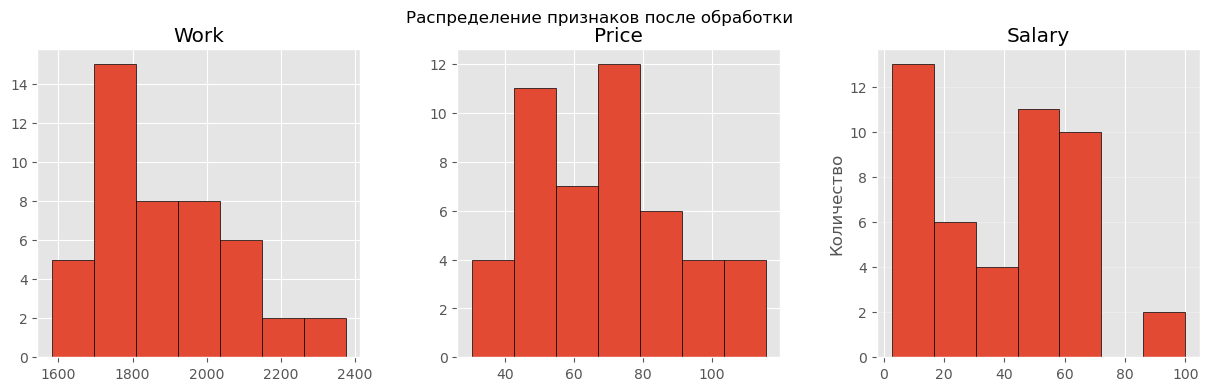

In [12]:
# отлично, выбросы заменены на NaN, Гонконг не трогаем
# проверю, изменилась ли диаграмма

df_nan[cols].hist(bins='sturges', edgecolor='black', figsize=(15, 4), layout=(1, 3))

plt.suptitle('Распределение признаков после обработки')
plt.ylabel('Количество')
plt.grid(axis='y', alpha=0.3)
plt.show()

df_descr_2 = df_nan.describe()

In [13]:
display(df_descr_1, df_descr_2) 

,Work,Price,Salary
count,48.000000,48.000000,48.000000
mean,1384.958333,68.860417,-378.727083
std,2404.897007,21.784659,2027.338052
min,-9999.000000,30.300000,-9999.000000
25%,1740.750000,49.650000,12.250000
50%,1834.500000,70.500000,40.300000
75%,1972.750000,81.700000,58.700000
max,2375.000000,115.500000,100.000000


,Work,Price,Salary
count,46.000000,48.000000,46.000000
mean,1879.913043,68.860417,39.545652
std,174.342552,21.784659,24.757703
min,1583.000000,30.300000,2.700000
25%,1745.250000,49.650000,14.375000
50%,1849.000000,70.500000,43.650000
75%,1976.250000,81.700000,59.700000
max,2375.000000,115.500000,100.000000


Выбросов больше нет.

У цен почти сходятся среднее и медиана, по зарплате - наибольшее число работников получает низкую зарплату

Salary = 100 у Цюриха по определению, индекс считается относительно Цюриха

In [14]:
# дроп NaN
clean = df_nan.dropna()
display(clean.head(), clean.describe())

,Work,Price,Salary
City,,,
Amsterdam,1714.0,65.6,49.0
Athens,1792.0,53.8,30.4
Bogota,2152.0,37.9,11.5
Bombay,2052.0,30.3,5.3
Brussels,1708.0,73.8,50.5


,Work,Price,Salary
count,46.000000,46.000000,46.000000
mean,1879.913043,70.100000,39.545652
std,174.342552,21.389177,24.757703
min,1583.000000,30.300000,2.700000
25%,1745.250000,51.775000,14.375000
50%,1849.000000,70.950000,43.650000
75%,1976.250000,81.900000,59.700000
max,2375.000000,115.500000,100.000000


In [15]:
# Work измеряется в часах (стандартное отклонение 174.3), 
# Price и Salary — в индексах (21.3 и 24.7)

# Разница в 100 часов «весит» в расстоянии столько же, сколько разница в 100 пунктов зарплаты, 
# хотя 100 часов — это небольшое отличие, а 100 пунктов зарплаты — разница между Цюрихом и Лагосом.

# Евклидово расстояние складывает квадраты разниц по каждому признаку. 
# Если признаки в разных единицах, побеждает тот, у которого числа больше, поэтому нужно стандартизовать данные

In [16]:
clean[clean.isna().any(axis=1)] # проверка, все ли NaN удалены

,Work,Price,Salary
City,,,


In [17]:
# так как удалены 2 города, нужно создать индексы для новой таблицы
labels_drop = clean.index.tolist()

## Кластеризация и сравнение подходов

### Без стандартизации

In [18]:
# вклад признака в сумму квадратов расстояний пропорционален его дисперсии
# какую долю расстояния «забирает» каждый признак, %
display((clean.var() / clean.var().sum() * 100).round(1)) 

Work      96.6
Price      1.5
Salary     1.9
dtype: float64

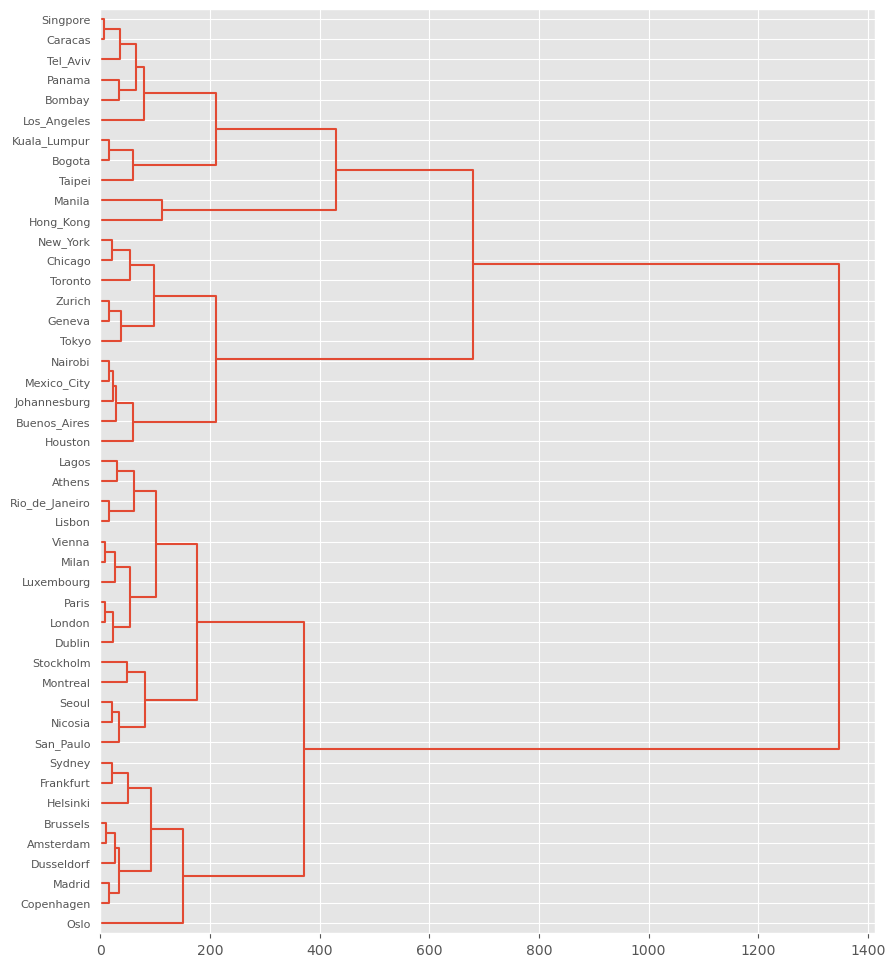

In [19]:
link = linkage(clean, 'ward', 'euclidean') # кластеризация чистых данных

# сразу визуализирую
fig = plt.figure(figsize=(10,12))
dn_1 = dendrogram(link, color_threshold = -1, labels=labels_drop, orientation='right')

[   6.29285309    7.47328576    8.30662386   10.27083249   14.69353599
   14.80033783   14.8882504    15.96558799   16.09099127   20.163829
   20.40882162   20.67776584   22.59063228   23.42313671   25.94609797
   26.09323028   28.46565182   29.61840644   33.24845861   33.91532594
   34.64582707   34.74977218   37.66209412   47.60640713   49.63903034
   53.09215259   53.2601477    59.14997887   59.75115062   61.62665819
   64.18000727   78.56235316   82.14480304   91.71954899   96.76433572
  101.59464061  112.16897967  150.62995681  175.82934909  210.62902402
  210.96355925  370.62286619  429.09318618  679.88286023 1346.80219964]


Text(0, 0.5, 'Расстояние')

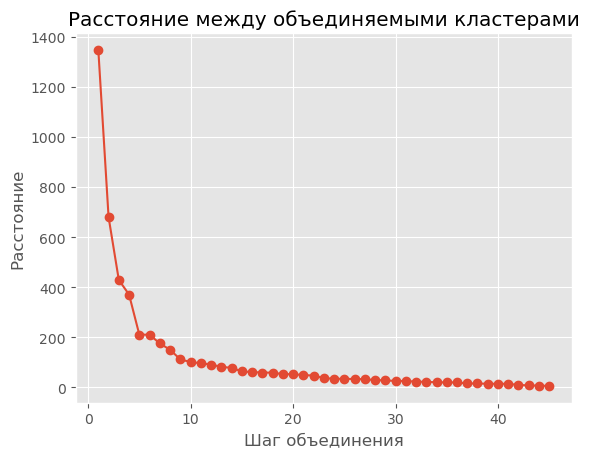

In [20]:
dist = link[:, 2]
print(dist)

dist_rev = dist[::-1]
idxs = range(1, len(dist) + 1) 
plt.plot(idxs, dist_rev, marker='o')
plt.title('Расстояние между объединяемыми кластерами')
plt.xlabel('Шаг объединения')
plt.ylabel('Расстояние')

In [21]:
# приведу размеры и разницу в удобный для чтения вид
df_dist = pd.DataFrame({
    "Число кластеров" : np.arange(2, 11), # от 2 до 10 кластеров, чтобы вывести первые 9 расстояний
    "Расстояние" : dist_rev[:9], # первые 9 строк из развернутого  списка
    
    # модуль разницы между расстояниями чтобы определить количество кластеров по большим изломам    
    "Разница" : np.abs(np.diff(dist_rev[:10]))
})
df_dist.style.background_gradient(subset=['Разница'])

,Число кластеров,Расстояние,Разница
0,2,1346.802200,666.919339
1,3,679.882860,250.789674
2,4,429.093186,58.470320
3,5,370.622866,159.659307
4,6,210.963559,0.334535
5,7,210.629024,34.799675
6,8,175.829349,25.199392
7,9,150.629957,38.460977
8,10,112.168980,10.574339


после главных скачков (k=2 и k=3) следующий заметный скачок 159.7 при k=5, дальше кривая пологая

In [22]:
# Посчитаем середину между слияниями в 5 кластеров

k = 5 # число кластеров

# середина между слияниями (k+1→k) и (k→k-1)
t = (link[-k, 2] + link[-(k-1), 2]) / 2
print(f'Порог для {k} кластеров: {t:.2f}')

Порог для 5 кластеров: 290.79


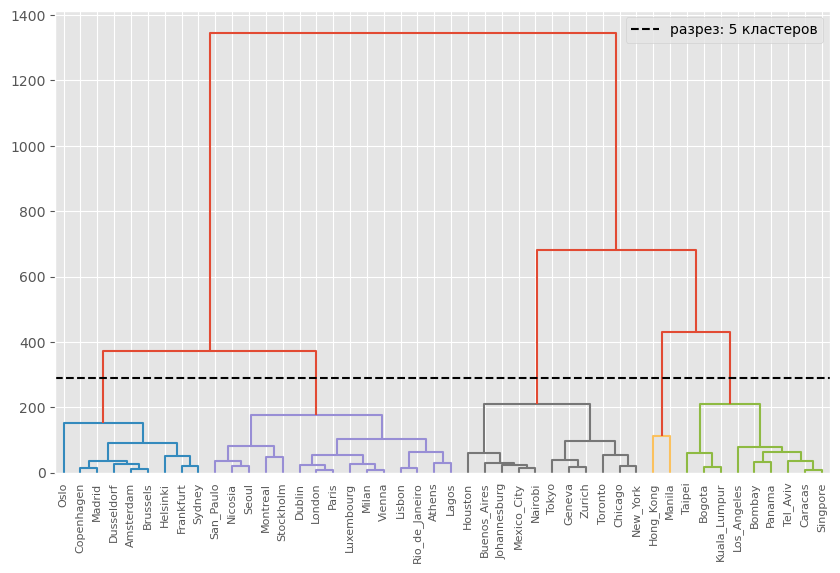

In [23]:
fig = plt.figure(figsize=(10, 6))
dn_1_1 = dendrogram(link, color_threshold = t, labels=labels_drop)
plt.axhline(y=t, color='black', linestyle='dashed', label=f'разрез: {k} кластеров') 
plt.legend()

### Стандартизация

In [24]:
from sklearn import preprocessing

# z-оценка устойчивее к одиночным крайним значениям, чем нормализация через MinMax
stand_1 = preprocessing.StandardScaler()

# вычисляем параметры стандартизации (они сохраняются внутри объекта stand_1)
stand_1.fit(clean)
# преобразуем данные
X = stand_1.transform(clean)
# Получаем стандартизованные данные в виде матрица numpy
# Преобразуем её в объект класса pandas.DataFrame.
X = pd.DataFrame(X, index=clean.index, columns=clean.columns)

display(X)

,Work,Price,Salary
City,,,
Amsterdam,-0.962166,-0.212712,0.386095
Athens,-0.509827,-0.770489,-0.373488
Bogota,1.577891,-1.522069,-1.145323
Bombay,0.997969,-1.881316,-1.398517
Brussels,-0.996961,0.174896,0.447351
Buenos_Aires,0.528233,-0.661769,-1.104485
Caracas,0.934178,-0.430150,-1.169825
Chicago,0.255670,0.179623,0.912902
Copenhagen,-0.944768,1.002108,0.953740


In [25]:
# какую долю расстояния «забирает» каждый признак, %
display((X.var() / X.var().sum() * 100).round(1))

Work      33.3
Price     33.3
Salary    33.3
dtype: float64

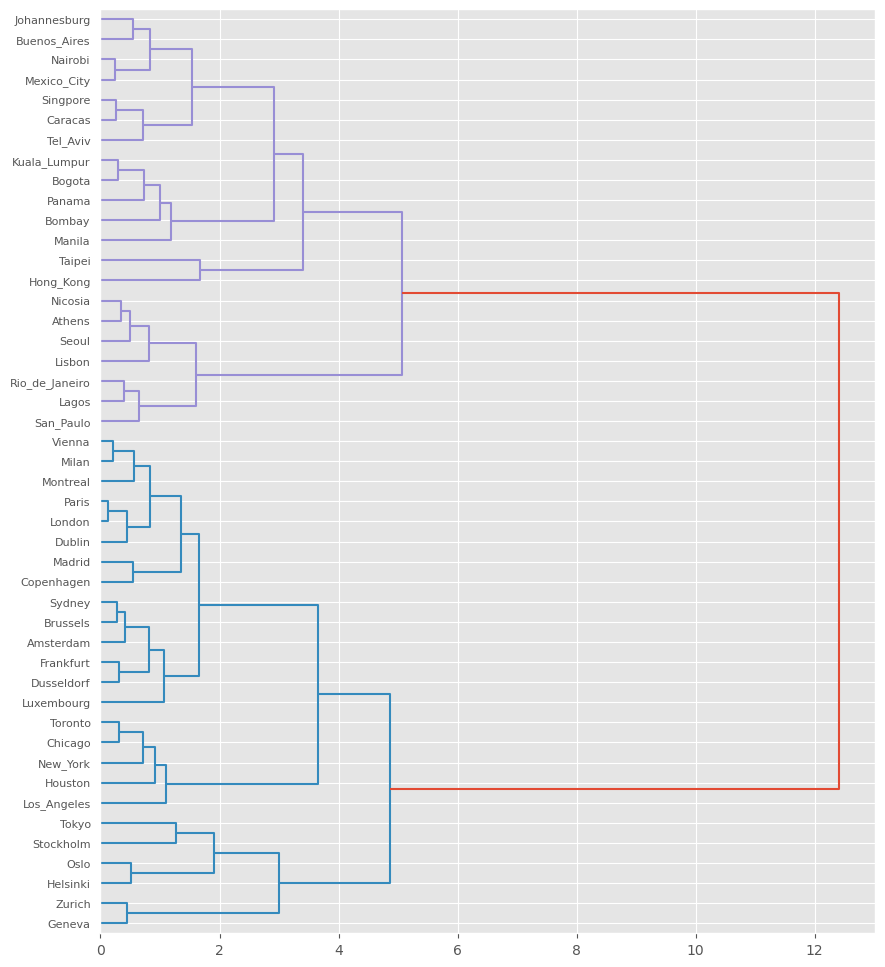

In [26]:
link_clean_stand = linkage(X, 'ward', 'euclidean') # кластеризация стандартизованных данных

# сразу визуализирую
fig = plt.figure(figsize=(10,12))

# опустим color_threshhold чтобы алгоритм сам разделил на кластеры
dn_2 = dendrogram(link_clean_stand, labels=labels_drop, orientation='right')

Алгоритм по умолчанию раскрашивает ветки ниже 70% от максимальной высоты, в нашем случае он подсказывает что кластера 2

Размер link_clean_stand: (45, 4)

[ 0.13000932  0.20992596  0.24101549  0.26638013  0.27962161  0.28619313
  0.31145704  0.31305006  0.3489377   0.38756772  0.419298    0.44645167
  0.45306282  0.4905399   0.50930475  0.54142314  0.54694673  0.55560294
  0.6525312   0.70695573  0.71322146  0.73106836  0.80923253  0.81996004
  0.83440954  0.83591396  0.92010068  1.00797757  1.07317494  1.09798639
  1.18557963  1.2661125   1.34552527  1.5346713   1.60218207  1.65009621
  1.67120837  1.9067302   2.91093293  2.99369803  3.40166518  3.65965497
  4.85967779  5.06109685 12.40027153]


Text(0, 0.5, 'Расстояние')

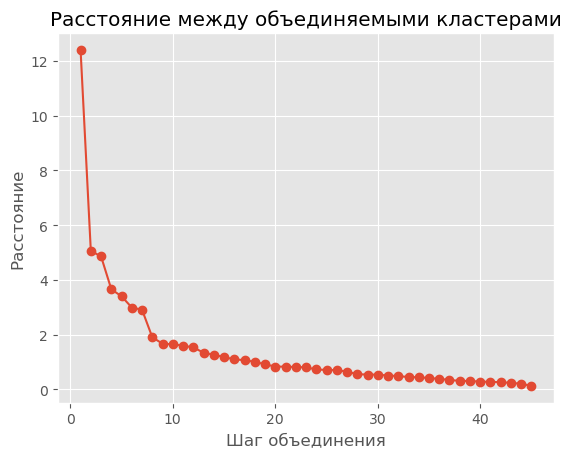

In [27]:
print(f'Размер link_clean_stand: {link_clean_stand.shape}\n')

dist_2 = link_clean_stand[:, 2] # дистанции в отдельную переменную
print(dist_2)


dist_rev_2 = dist_2[::-1] # разворот расстояний
idxs_2 = range(1, len(dist_2) + 1)
plt.plot(idxs_2, dist_rev_2, marker='o')
plt.title('Расстояние между объединяемыми кластерами')
plt.xlabel('Шаг объединения')
plt.ylabel('Расстояние')

In [28]:
# приведу размеры и разницу в удобный для чтения вид
df_dist_stand = pd.DataFrame({
    "Число кластеров" : np.arange(2, 11), # от 2 до 10 кластеров, чтобы вывести первые 9 расстояний
    "Расстояние" : dist_rev_2[:9], # первые 9 строк из развернутого  списка
    
    # модуль разницы между расстояниями чтобы определить количество кластеров по большим изломам    
    "Разница" : np.abs(np.diff(dist_rev_2[:10]))
})
df_dist_stand.style.background_gradient(subset=['Разница'])

,Число кластеров,Расстояние,Разница
0,2,12.400272,7.339175
1,3,5.061097,0.201419
2,4,4.859678,1.200023
3,5,3.659655,0.257990
4,6,3.401665,0.407967
5,7,2.993698,0.082765
6,8,2.910933,1.004203
7,9,1.906730,0.235522
8,10,1.671208,0.021112


Наибольший скачок при k=2 (7.34), второй по величине при k=4 (1.20). 

Больших скачков после слияния в 4 кластера нет, оставляем 4 кластера

In [29]:
# Посчитаем середину между слияниями в 4 кластера

k = 4 # число кластеров

# середина между слияниями (k+1→k) и (k→k-1)
m = (link_clean_stand[-k, 2] + link_clean_stand[-(k-1), 2]) / 2
print(f'Порог для {k} кластеров: {m:.2f}')

Порог для 4 кластеров: 4.26


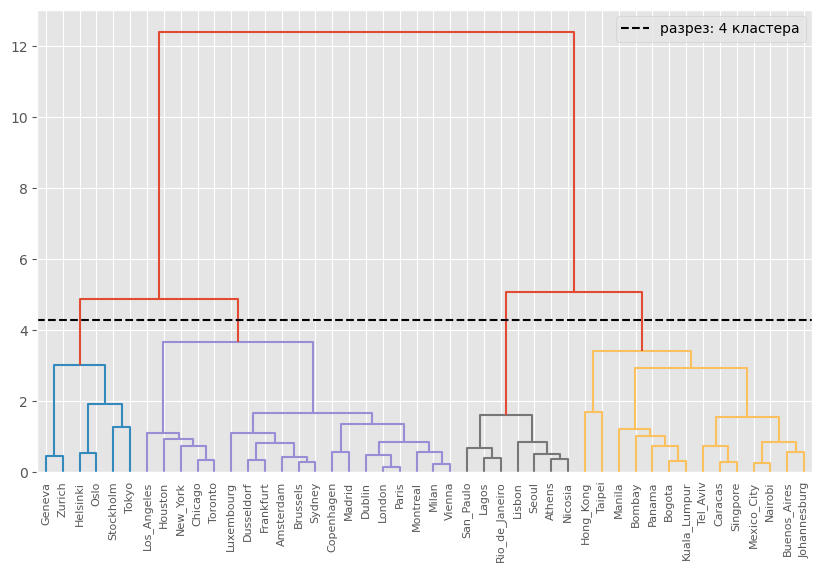

In [30]:
fig = plt.figure(figsize=(10, 6))
dn = dendrogram(link_clean_stand, # кластеризация
                labels=labels_drop, # названия городов
                color_threshold=m, # линия разреза - середина между слияниями
)

plt.axhline(y=m, color='black', linestyle='--', label=f'разрез: {k} кластера') 
plt.legend()

In [31]:
# проверяем, как 4 кластера ложатся на 2
pd.crosstab(fcluster(link_clean_stand, 2, criterion='maxclust'),
            fcluster(link_clean_stand, 4, criterion='maxclust'),
            rownames=['2 кластера'], colnames=['4 кластера'])

4 кластера,1,2,3,4
2 кластера,,,,
1,6,19,0,0
2,0,0,7,14


Каждый из 2 кластеров делится ровно на два, ни один город не перескочил. То есть 4 кластера это те же 2, только подробнее.

## Интерпретация кластеров

In [32]:
# копирую таблицу до нормализации, чтобы в копию занести столбец "кластеры"
df_clean = clean.copy()

# номера кластеров превращаем в текст для графиков, они в номинальны
# maxclust пототму что заранее определили число кластеров
df_clean['cluster'] = fcluster(link, 5, criterion='maxclust').astype(str) # без стандартизации
df_clean['cluster_2'] = fcluster(link_clean_stand, 4, criterion='maxclust').astype(str) # после стандартизации

In [33]:
df_clean.groupby('cluster')[cols].mean() # сводная таблица cо средними значениями

,Work,Price,Salary
cluster,,,
1,1678.888889,86.377778,57.266667
2,1785.666667,67.566667,35.946667
3,1925.272727,73.836364,48.954545
4,2321.500000,51.900000,15.900000
5,2084.444444,57.522222,21.577778


In [34]:
df_clean.groupby('cluster_2')[cols].mean() # сводная таблица cо средними значениями

,Work,Price,Salary
cluster_2,,,
1,1780.500000,108.550000,71.300000
2,1792.000000,77.526316,55.157895
3,1798.857143,50.942857,19.214286
4,2082.357143,53.121429,14.914286


In [35]:
#  Выводим состав кластеров до стандартизации для всей выборки
df_clean['cluster'].sort_values()

City
Amsterdam         1
Madrid            1
Helsinki          1
Frankfurt         1
Dusseldorf        1
Copenhagen        1
Oslo              1
Brussels          1
Sydney            1
Paris             2
San_Paulo         2
Vienna            2
Seoul             2
Nicosia           2
Stockholm         2
Montreal          2
Milan             2
Rio_de_Janeiro    2
London            2
Luxembourg        2
Lagos             2
Athens            2
Lisbon            2
Dublin            2
Toronto           3
Tokyo             3
Buenos_Aires      3
Chicago           3
Geneva            3
Zurich            3
Nairobi           3
Houston           3
Mexico_City       3
Johannesburg      3
New_York          3
Hong_Kong         4
Manila            4
Caracas           5
Bombay            5
Singpore          5
Bogota            5
Taipei            5
Tel_Aviv          5
Kuala_Lumpur      5
Los_Angeles       5
Panama            5
Name: cluster, dtype: object

In [36]:
#  Выводим состав кластеров после стандартизации для всей выборки
df_clean['cluster_2'].sort_values()

City
Zurich            1
Tokyo             1
Stockholm         1
Oslo              1
Geneva            1
Helsinki          1
Toronto           2
Sydney            2
Paris             2
New_York          2
Montreal          2
Milan             2
Madrid            2
Vienna            2
Los_Angeles       2
London            2
Amsterdam         2
Luxembourg        2
Brussels          2
Chicago           2
Copenhagen        2
Dusseldorf        2
Dublin            2
Houston           2
Frankfurt         2
Athens            3
San_Paulo         3
Lisbon            3
Nicosia           3
Lagos             3
Rio_de_Janeiro    3
Seoul             3
Bogota            4
Tel_Aviv          4
Taipei            4
Bombay            4
Singpore          4
Kuala_Lumpur      4
Panama            4
Johannesburg      4
Nairobi           4
Mexico_City       4
Manila            4
Hong_Kong         4
Buenos_Aires      4
Caracas           4
Name: cluster_2, dtype: object

In [37]:
# сравниваем кластеры до и после стандартизации
pd.crosstab(
    df_clean['cluster'], 
    df_clean['cluster_2'], 
    rownames=['без стандартизации'], 
    colnames=['после стандартизации'])

после стандартизации,1,2,3,4
без стандартизации,,,,
1,2,7,0,0
2,1,7,7,0
3,3,4,0,4
4,0,0,0,2
5,0,1,0,8


Кластеры до и после стандартизации почти не совпадают. Без стандартизации в кластере 3 оказались Цюрих, Женева и Токио вместе с Найроби и Мехико, их объединяют только похожие рабочие часы (Work забирает 96.6% расстояния). Гонконг и Манила вообще отдельный кластер из-за рекордных часов. Дальше смотрим только кластеры после стандартизации.

In [38]:
# средние, медианы и размер кластеров
prof = df_clean.groupby('cluster_2')[cols].agg(['mean', 'median']).round(1)
prof['Городов'] = df_clean.groupby('cluster_2').size()
display(prof)

Work          Price        Salary        Городов
             mean  median   mean median   mean median        
cluster_2                                                    
1          1780.5  1836.5  108.6  112.4   71.3   67.3       6
2          1792.0  1759.0   77.5   76.0   55.2   53.3      19
3          1798.9  1792.0   50.9   48.9   19.2   18.8       7
4          2082.4  2047.0   53.1   50.4   14.9   12.0      14

Кластеры 1 и 2 выше среднего по ценам и зарплатам, 3 и 4 ниже. Часы выше среднего только у кластера 4 (+11%), у остальных чуть ниже среднего.

### Силуэт

Для каждого города смотрим, насколько он ближе к своему кластеру, чем к соседнему:

,Без стандартизации,Со стандартизацией
Число кластеров,,
2,0.252000,0.470000
3,0.185000,0.361000
4,0.125000,0.355000
5,0.046000,0.348000
6,-0.008000,0.366000
7,0.018000,0.396000
8,0.001000,0.399000


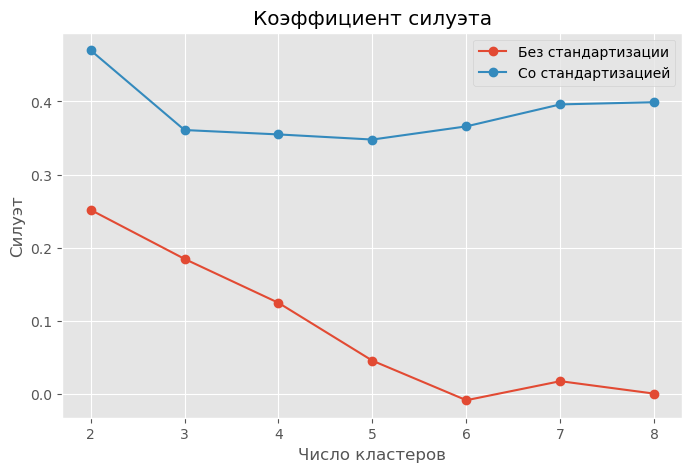

In [39]:
from sklearn.metrics import silhouette_score

rows = []
for k in range(2, 9):
    c_raw = fcluster(link, k, criterion='maxclust')
    c_std = fcluster(link_clean_stand, k, criterion='maxclust')
    rows.append({
        'Число кластеров': k,
        # оба разбиения оцениваем в стандартизованном пространстве,
        # где все признаки равноправны, иначе сравнение нечестное
        'Без стандартизации': silhouette_score(X, c_raw),
        'Со стандартизацией': silhouette_score(X, c_std),
    })
    
sil = pd.DataFrame(rows).set_index('Число кластеров').round(3) # заворчиваем в датафрейм
display(sil.style.background_gradient()) # градиент 

ax = sil.plot(marker='o', figsize=(8, 5))
ax.set_title('Коэффициент силуэта')
ax.set_ylabel('Силуэт')
plt.show()

Cтандартизованная кластеризация лучше при любом k. Формальный максимум при k=2. 

При k=4 силуэт почти такой же, как при 3 и 5, но интерпретация богаче.

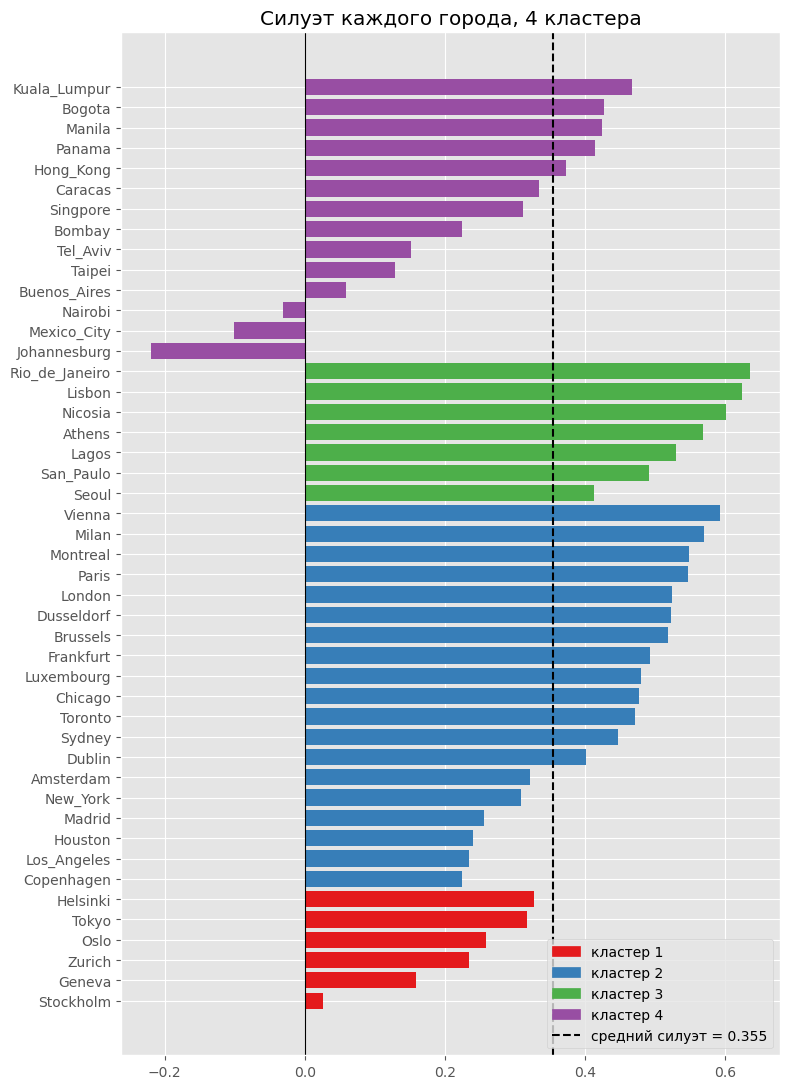

Кластер
1    0.22
2    0.43
3    0.55
4    0.21
Name: Силуэт, dtype: float64

In [40]:
from sklearn.metrics import silhouette_samples
from matplotlib.patches import Patch

order = ['1', '2', '3', '4']
# словарь номер кластера
# берём те же 4 цвета Set1, что seaborn ставит на скаттерах, чтобы кластер 1 везде был одного цвета
palette = dict(zip(order, sns.color_palette('Set1', 4)))

# силуэт каждого города при 4 кластерах
sil_city = pd.DataFrame({
    'Силуэт': silhouette_samples(X, df_clean['cluster_2']), # силуэт каждого города отдельно
    'Кластер': df_clean['cluster_2'],
}, index=df_clean.index).sort_values(['Кластер', 'Силуэт'])

fig, ax = plt.subplots(figsize=(8, 11))
ax.barh(sil_city.index, sil_city['Силуэт'], color=sil_city['Кластер'].map(palette))
mean_line = ax.axvline(sil_city['Силуэт'].mean(), color='black', linestyle='--',
                       label=f'средний силуэт = {sil_city["Силуэт"].mean():.3f}')
ax.axvline(0, color='black', linewidth=0.8)
ax.legend(handles=[Patch(color=palette[c], label=f'кластер {c}') for c in order] + [mean_line], loc='lower right')
ax.set_title('Силуэт каждого города, 4 кластера')
plt.tight_layout()
plt.show()

sil_city.groupby('Кластер')['Силуэт'].mean().round(2) # средний силуэт по кластерам

Хуже всего сидят Йоханнесбург, Мехико и Найроби (силуэт меньше 0): по ценам и зарплатам они похожи и на кластер 3, и на кластер 4, а по часам где-то посередине. Самый плотный кластер 3, самые рыхлые 1 и 4.

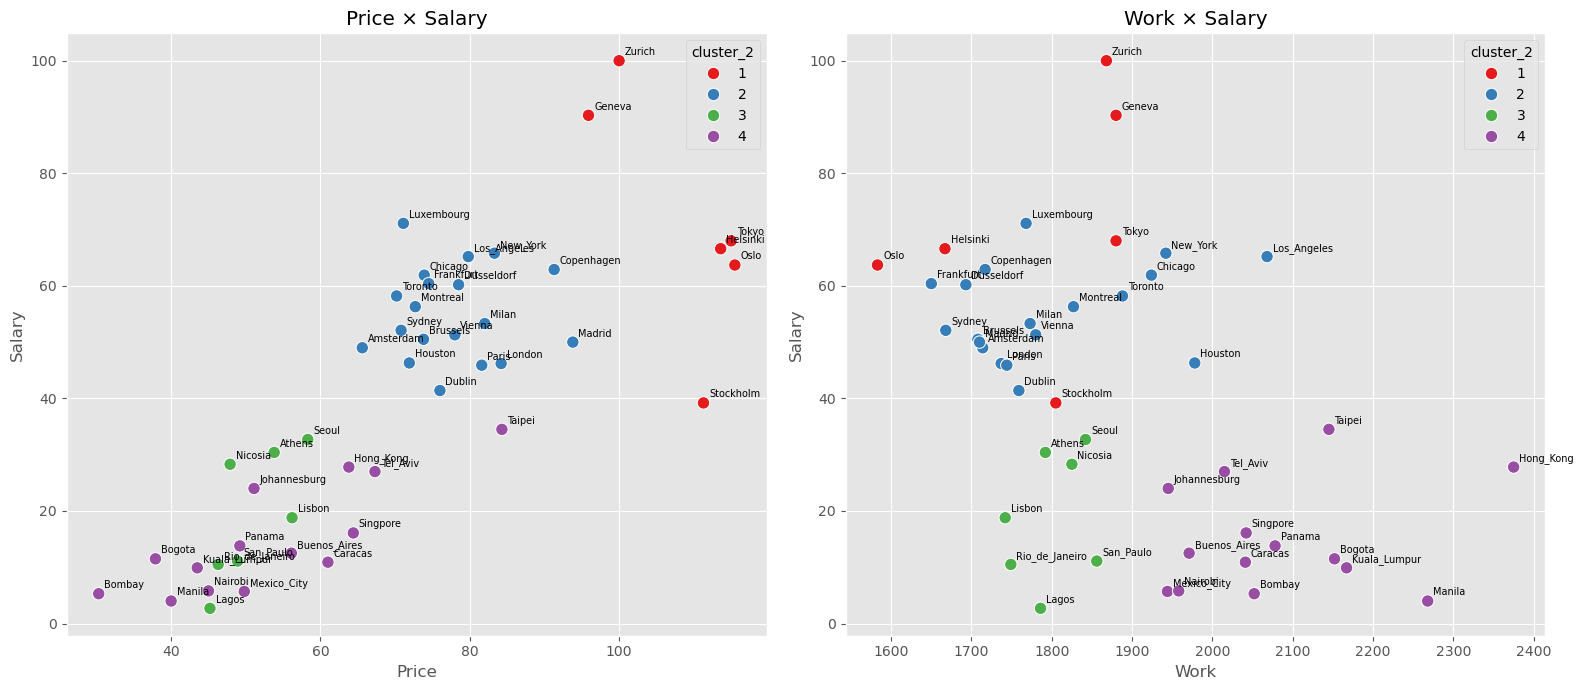

In [59]:
# порядок кластеров, кластеры у нас строки, 
# без него seaborn берёт их в порядке появления в таблице и цвета прыгают
order = ['1', '2', '3', '4'] 

# hue - красим точки по кластеру, 
# hue_order - в каком порядке раздавать цвета, 
# palette - набор цветов, 
# s - размер точек

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (x, y) in zip(axes, [('Price', 'Salary'), ('Work', 'Salary')]):
    sns.scatterplot(data=df_clean, x=x, y=y, hue='cluster_2', hue_order=order, palette='Set1', s=80, ax=ax)
    
    # подписываем каждый город рядом с точкой
    for city, row in df_clean.iterrows():
        ax.annotate(city, (row[x], row[y]), fontsize=7,
                    xytext=(4, 4), textcoords='offset points')
    ax.set_title(f'{x} × {y}')
plt.tight_layout()
plt.show()

Слева кластеры 3 и 4 перемешаны, по ценам и зарплатам они одинаковые. Справа они расходятся по горизонтали: кластер 3 работает около 1800 часов, кластер 4 около 2080.

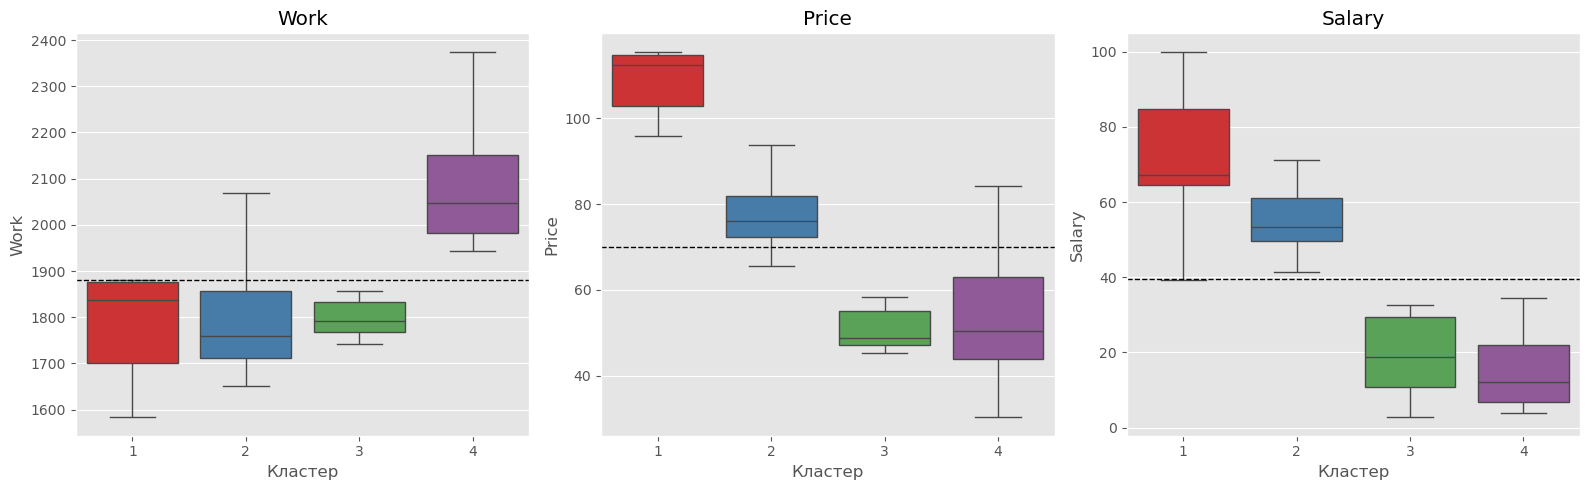

In [42]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, cols):
    sns.boxplot(data=df_clean, 
                x='cluster_2', 
                y=col, 
                hue='cluster_2', # красим ящики по кластеру (без hue seaborn ругается на palette)
                order=order, # порядок ящиков по оси x
                hue_order=order, # порядок цветов, чтобы совпадал с x
                palette='Set1', # те же цвета, что на скаттерах
                legend=False, # легенда не нужна, номер кластера и так подписан на оси
                ax=ax)
    ax.axhline(clean[col].mean(), color='black', linestyle='--', linewidth=1)
    ax.set_title(col)
    ax.set_xlabel('Кластер')
plt.tight_layout()
plt.show()

In [43]:
clean[cols].corr().round(2) # корреляции признаков

,Work,Price,Salary
Work,1.00,-0.45,-0.46
Price,-0.45,1.00,0.80
Salary,-0.46,0.80,1.00


### Описание кластеров

1. Самые дорогие и с самыми высокими зарплатами (6) Цюрих, Женева, Токио, Осло, Стокгольм, Хельсинки.
2. Развитые города (19) Лондон, Париж, Нью-Йорк, Франкфурт, Сидней и т.д., цены и зарплаты выше среднего.
3. Небогатые с обычным рабочим годом (7) Афины, Лиссабон, Никосия, Сеул, Рио, Сан-Паулу, Лагос.
4. Небогатые, но работают дольше всех (14) Гонконг, Сингапур, Тайбэй, Манила, Бомбей, Богота, Мехико и др.

Можно интерпретировать как богатых и бедных, но только на двух кластерах. Главное различие в ценах и зарплатах, а они сильно связаны между собой. Но на 4 кластерах богатые делятся по тому, насколько они богатые, а бедные по рабочему времени 

у 3 и 4 почти одинаковые цены (51 и 53) и зарплаты (19 и 15), но в 4 работают почти на 300 часов в год больше.

## Выводы

Каир и Джакарта удалены, у них заглушки −9999 в двух признаках из трёх. Гонконг оставили. В датасете46 городов.

Без стандартизации Work забирает 96.6% расстояния, потому что часы измеряются тысячами, а индексы цен и зарплат десятками. Кластеры собираются по часам, Цюрих попадает в один кластер с Найроби, силуэт 0.05–0.13. После стандартизации каждый признак даёт по 33%, поэтому дальше работали со стандартизованными данными.

Формально лучше 2 кластера, самый большой скачок на дендрограмме (7.34) и самый большой силуэт (0.47).

Мы взяли 4, там второй излом (1.20), силуэт 0.355, и 4 кластера это те же 2, только поделённые пополам, так что их проще описать.

Получились самые дорогие города (6), развитые (19), небогатые с обычным рабочим годом (7) и небогатые с длинным рабочим годом (14). На 2 кластерах это богатые и бедные, потому что цены и зарплаты сильно связаны (корреляция 0.8) и вместе дают главное различие. На 4 кластерах бедные делятся уже не по деньгам, а по часам работы.